# 03 - Explaining the model (SHAP) and choosing who gets a coupon

1. **Why** does the model call a household risky? (SHAP)
2. **Who** should get a coupon: the households most likely to churn, or the ones we would lose the most sales on?

Run `python -m src.train` first: it writes the final model and the test-week scores.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
import joblib
from src.config import MODEL_PATH, PROCESSED_DIR, REPORTS_DIR
from src.features import FEATURES

model = joblib.load(MODEL_PATH)                              # final model, refit on all labelled snapshots
test = pd.read_csv(PROCESSED_DIR / "test_scores.csv")       # test week, scored by models trained BEFORE it
chosen = pd.read_csv(REPORTS_DIR / "validation_results.csv", index_col="model").drop("recency_rule")["valid_pr_auc"].idxmax()
y = test["churn"].to_numpy()
risk = test[f"score_{chosen}"].to_numpy()
print(chosen, "| test households:", len(test), "| churn rate:", f"{y.mean():.1%}")

random_forest | test households: 2316 | churn rate: 8.2%


## 1. SHAP: which features push the risk up or down?

SHAP splits each prediction into a contribution per feature. Positive = pushes towards churn, negative = away from churn.
We explain the **final model** on the households it actually scores: the ones at risk in the latest week of the data.

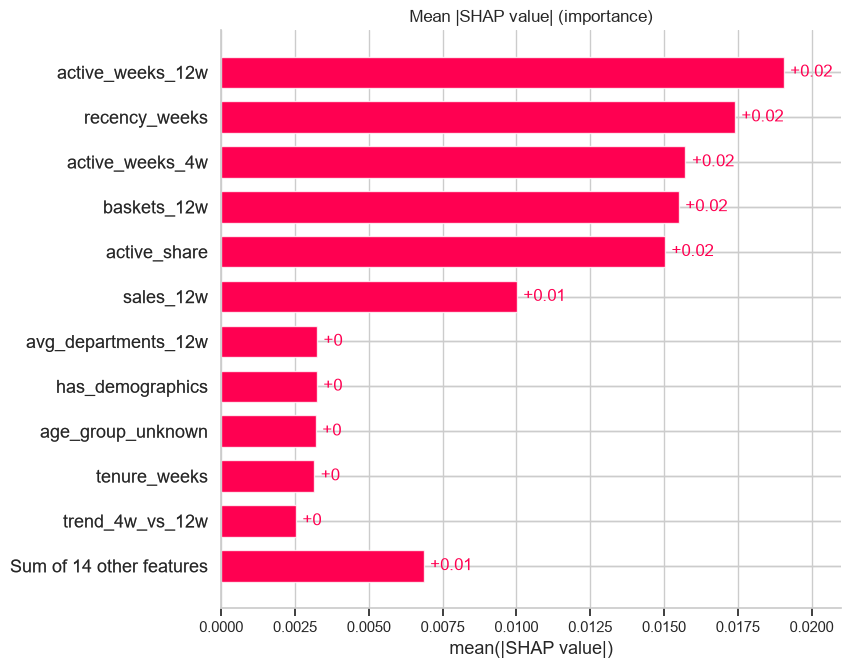

In [3]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless message from the shap import
import shap
from src.features import build_scoring_table, load_inputs

weekly, demographics = load_inputs()
latest = build_scoring_table(weekly, demographics, cutoff=int(weekly["week_no"].max()))
X = pd.DataFrame(model["prep"].transform(latest[FEATURES]), columns=model["prep"].get_feature_names_out())
sample = X.sample(800, random_state=0)
clf = model[-1]
if hasattr(clf, "coef_"):          # linear model
    explainer = shap.LinearExplainer(clf, X.sample(200, random_state=1))
else:                              # tree models (random forest, LightGBM)
    explainer = shap.TreeExplainer(clf)
sv = explainer(sample)
if sv.values.ndim == 3:            # some tree models return one set of values per class: keep the "churn" class
    sv = sv[:, :, 1]

shap.plots.bar(sv, max_display=12, show=False)
plt.title("Mean |SHAP value| (importance)")
plt.show()

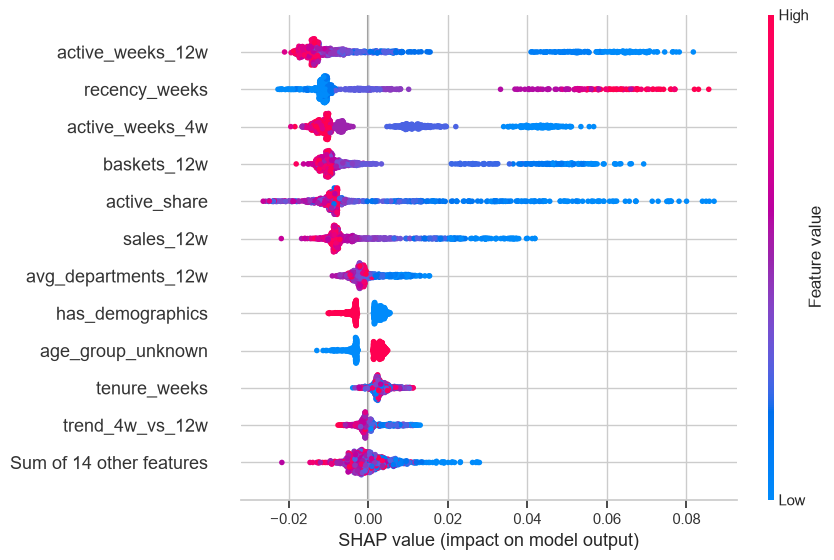

In [4]:
shap.plots.beeswarm(sv, max_display=12, show=False)
fig = plt.gcf()
fig.savefig(FIGURES_DIR / "shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

How to read the beeswarm: each dot is one household; red = high feature value, blue = low.
For example, red dots of `recency_weeks` sit on the right: a long time since the last purchase raises the predicted risk.
Values are on the standardized / log scale used inside the pipeline.

The demographic *values* (income, age group, household size) matter very little. What the model does use is whether demographics are
**missing** (`age_group_unknown`, `has_demographics`): the possible data-collection bias found in notebook 02. SHAP makes this visible,
which is one of the main reasons to explain a model before using it.

### Explaining one household

SHAP also explains a **single** prediction. Below: the riskiest household in the sample.
The base value is the average prediction; each bar pushes it up (red) or down (blue).

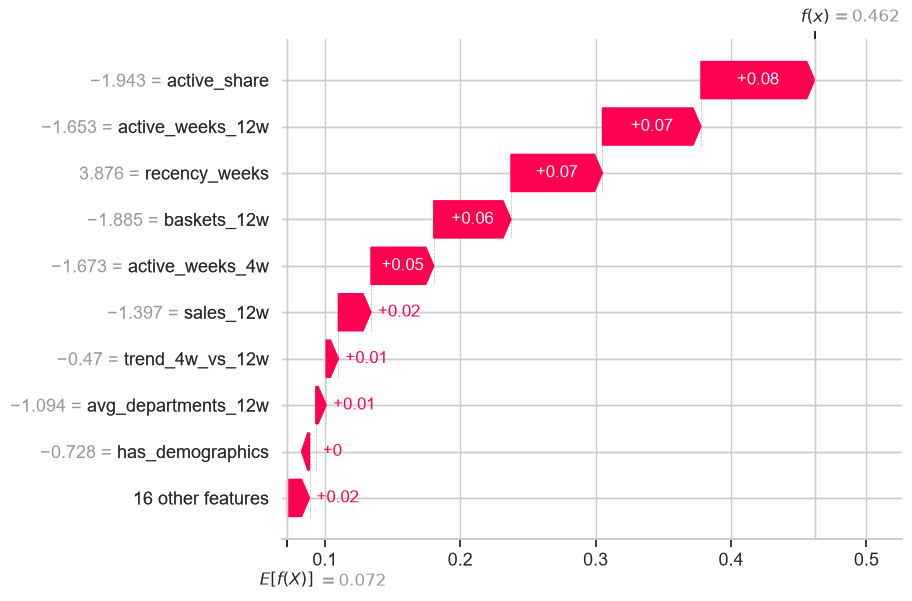

,value (original scale)
recency_weeks,10.000
active_weeks_12w,1.000
active_share,0.053
sales_12w,36.860


In [5]:
riskiest = int(np.argmax(sv.values.sum(axis=1)))
shap.plots.waterfall(sv[riskiest], max_display=10, show=False)
plt.show()
latest.loc[sample.index[riskiest], ["recency_weeks", "active_weeks_12w", "active_share", "sales_12w"]].to_frame("value (original scale)")

## 2. Who should get a coupon?

The same predictions can be ranked in two ways:
* **by churn risk**: the churn probability;
* **by expected sales lost** = churn probability x `sales_12w`: losing a big spender costs the store more than losing a small one.

For each budget (top 5%, 10%, ...) we count the real churners reached and their **sales at risk** (what those churners spent in the last 12 weeks).
We do **not** assume a coupon cost or how many churners a coupon keeps: only an A/B test can measure that.

In [6]:
from src.business import targeting_table

sales = test["sales_12w"].to_numpy()
print(f"median sales in the last 12 weeks: churners {np.median(sales[y == 1]):.0f} vs non-churners {np.median(sales[y == 0]):.0f}")
by_risk = targeting_table(y, risk, sales)
by_value = targeting_table(y, risk * sales, sales)
by_risk

median sales in the last 12 weeks: churners 65 vs non-churners 336


,share_targeted,households,churners_reached,share_of_all_churners,sales_at_risk_reached,share_of_sales_at_risk
0,0.05,115,45,0.238,1270.22,0.051
1,0.10,231,84,0.444,3716.52,0.149
2,0.20,463,128,0.677,7615.41,0.305
3,0.30,694,160,0.847,12925.98,0.518
4,0.50,1158,176,0.931,19066.35,0.765
5,1.00,2316,189,1.000,24931.74,1.000


In [7]:
by_value

,share_targeted,households,churners_reached,share_of_all_churners,sales_at_risk_reached,share_of_sales_at_risk
0,0.05,115,24,0.127,7212.55,0.289
1,0.10,231,42,0.222,10792.79,0.433
2,0.20,463,76,0.402,14631.81,0.587
3,0.30,694,105,0.556,16620.85,0.667
4,0.50,1158,144,0.762,18979.68,0.761
5,1.00,2316,189,1.000,24931.74,1.000


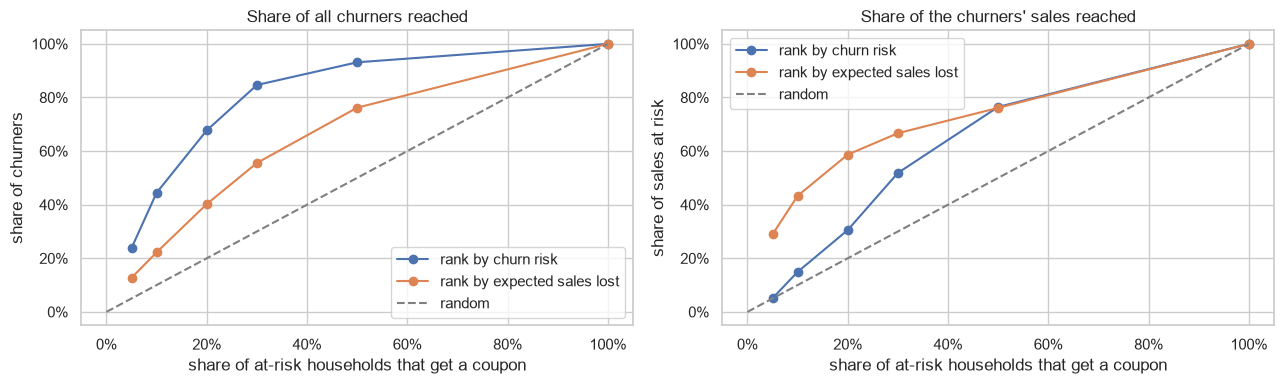

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for t, label in [(by_risk, "rank by churn risk"), (by_value, "rank by expected sales lost")]:
    axes[0].plot(t["share_targeted"], t["share_of_all_churners"], marker="o", label=label)
    axes[1].plot(t["share_targeted"], t["share_of_sales_at_risk"], marker="o", label=label)
axes[0].set(title="Share of all churners reached", ylabel="share of churners")
axes[1].set(title="Share of the churners' sales reached", ylabel="share of sales at risk")
for ax in axes:
    ax.plot([0, 1], [0, 1], ls="--", c="grey", label="random")
    ax.set(xlabel="share of at-risk households that get a coupon")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "targeting_curve.png", dpi=120, bbox_inches="tight")
plt.show()

**Trade-off:** ranking by risk reaches more churners (left), ranking by expected sales lost reaches more of the **sales** that would be lost (right).

### Does the model really help this decision?

Maybe "big spenders first" is enough and the model adds nothing. We compare with two rankings **without** the model,
all with the same budget (10% of the households):
* **sales only**: the biggest spenders first;
* **recency rule x sales**: the simple "longest silence first" rule instead of the model's risk.

In [9]:
from src.business import compare_rankings

rankings = {
    "churn risk (model)": risk,
    "expected sales lost (model)": risk * sales,
    "recency rule x sales (no model)": test["score_recency_rule"].to_numpy() * sales,
    "sales only (no model)": sales,
}
compare_rankings(y, rankings, sales)

,households,churners_reached,share_of_all_churners,share_of_sales_at_risk
churn risk (model),231.0,84.0,0.444,0.149
expected sales lost (model),231.0,42.0,0.222,0.433
recency rule x sales (no model),231.0,24.0,0.127,0.246
sales only (no model),231.0,2.0,0.011,0.130


* Ranking by **expected sales lost** reaches by far the largest share of the sales at risk.
* Without the model, "sales only" is barely better than random (big spenders rarely churn), and the recency rule reaches clearly
  less than the model. So the model's risk score is what makes the value-based ranking work.

Since the goal of the campaign is to protect revenue, the coupon list uses expected sales lost.
Whether the campaign is **worth its cost** depends on how many churners a coupon really keeps. That cannot be learned from this data:
the next step would be an **A/B test** (give the coupon to a random half of the list, compare churn after 8 weeks).

## 3. The coupon list for the latest week

`python -m src.predict` scores the households at risk in the last week of the data (week 102) with the saved model
and writes the top 10% by expected sales lost to `reports/coupon_list.csv`.

In [10]:
from src.predict import main as predict
predict([])
pd.read_csv("reports/coupon_list.csv").head(10)

Week 102: 2,310 households at risk -> coupon list of the top 10% (231 households)
mean churn probability in the list 15.7% vs 7.7% for all at-risk households
Wrote reports/coupon_list.csv


,household_key,churn_probability,sales_12w,expected_sales_lost,recency_weeks,active_weeks_12w
0,149,0.189,752.99,142.591,8,4.0
1,1016,0.253,508.09,128.550,8,2.0
2,2042,0.227,466.85,105.965,4,2.0
3,1629,0.415,228.46,94.810,7,1.0
4,910,0.307,285.05,87.487,10,1.0
5,700,0.078,1091.57,84.851,1,7.0
6,2251,0.240,340.04,81.701,7,2.0
7,1702,0.201,402.34,80.770,8,3.0
8,1140,0.347,215.21,74.680,7,2.0
9,2136,0.092,804.84,74.278,1,6.0


## Conclusions and next steps
* SHAP shows the model relies mostly on **recency, regularity and recent spend**, in a way that makes business sense.
  The "demographics missing" signal should be checked with the data owner before production.
* **Who** to target matters as much as the model: churners are mostly small spenders, so ranking by *risk x recent sales*
  reaches fewer churners but a much larger share of the sales at risk, and clearly more than the rankings without the model.
* The key unknown is **how many churners a coupon really keeps**. Only an A/B test can measure it.